In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (14, 4)
plt.rcParams["figure.dpi"] = 100

AUDIO_PATH = Path("/content/drive/MyDrive/[MUC] Automatic Piano Evaluation/data/wav/c_major_legato.wav")

SAMPLE_RATE = 22_050  # samples per second
HOP_LENGTH = 512      # samples between frames -> 512 / 22050 = 23 ms per frame
TRIM_TOP_DB = 50      # anything 50 dB quieter than the loudest part counts as silence

print(f"One frame = {HOP_LENGTH / SAMPLE_RATE * 1000:.1f} ms")

One frame = 23.2 ms


321,754 samples at 22050 Hz = 14.59 seconds


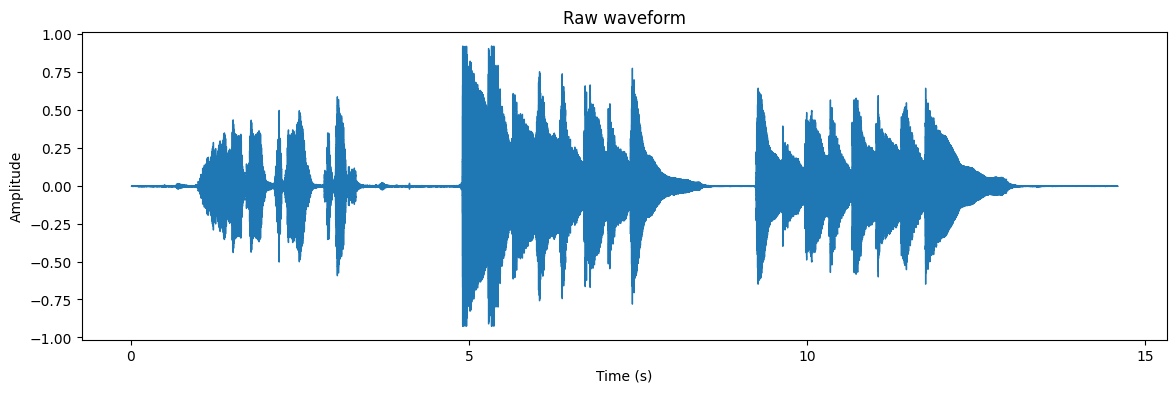

In [30]:
##### LOADING THE AUDIO #####

waveform, sr = librosa.load(AUDIO_PATH, sr=SAMPLE_RATE, mono=True)

print(f"{len(waveform):,} samples at {sr} Hz = {len(waveform) / sr:.2f} seconds")

fig, ax = plt.subplots()
librosa.display.waveshow(waveform, sr=sr, ax=ax)
ax.set(title="Raw waveform", xlabel="Time (s)", ylabel="Amplitude")
plt.show()

display(Audio(waveform, rate=sr))

In [31]:
# trimming

SIMULATE_RAW_RECORDING = True

if SIMULATE_RAW_RECORDING:
    rng = np.random.default_rng(0)
    noise_level = 0.0005 * np.max(np.abs(waveform))  # about 65 dB below the loudest note
    room_noise = lambda: noise_level * rng.standard_normal(sr)  # 1 s of quiet hiss
    waveform = np.concatenate([room_noise(), waveform, room_noise()])
    print(f"Padded to {len(waveform) / sr:.2f} seconds")

Padded to 16.59 seconds


Kept 1.44 s to 14.14 s (removed 1.44 s at the start and 2.45 s at the end)


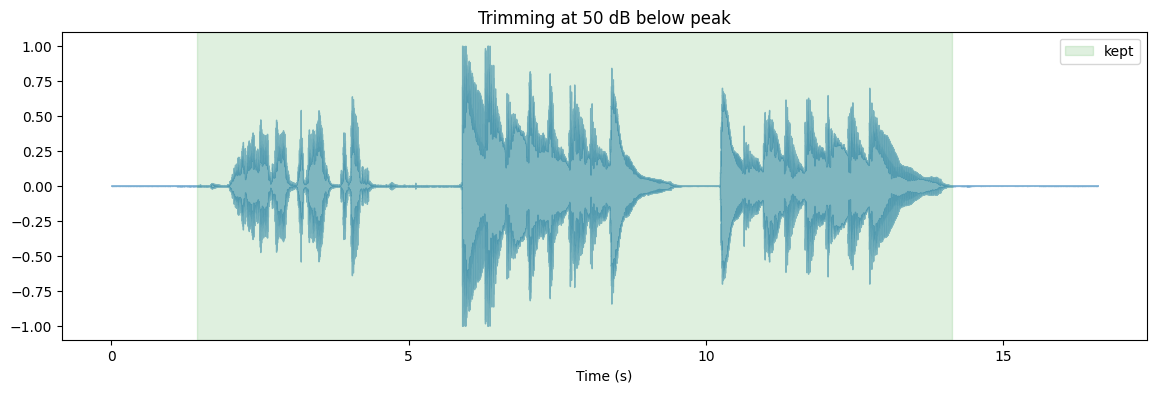

In [32]:
def normalize(signal):
    signal = signal - np.median(signal)
    peak = np.max(np.abs(signal))
    return signal / peak if peak > 0 else signal

waveform = normalize(waveform)
trimmed, (start, end) = librosa.effects.trim(waveform, top_db=TRIM_TOP_DB)
trimmed = normalize(trimmed)

print(f"Kept {start / sr:.2f} s to {end / sr:.2f} s "
      f"(removed {start / sr:.2f} s at the start and {(len(waveform) - end) / sr:.2f} s at the end)")

fig, ax = plt.subplots()
librosa.display.waveshow(waveform, sr=sr, ax=ax, alpha=0.5)
ax.axvspan(start / sr, end / sr, color="tab:green", alpha=0.15, label="kept")
ax.set(title=f"Trimming at {TRIM_TOP_DB} dB below peak", xlabel="Time (s)")
ax.legend(loc="upper right")
plt.show()

display(Audio(trimmed, rate=sr))

Mel spectrogram shape: (128, 530)  (mel bands, frames)


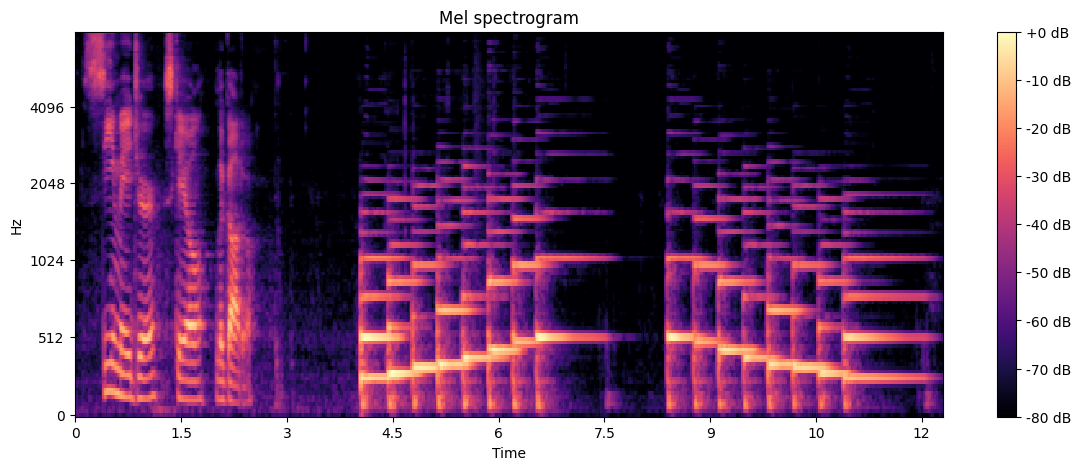

In [34]:
# generating mel specto gram
mel_power = librosa.feature.melspectrogram(
    y=trimmed, sr=sr, n_fft=2048, hop_length=HOP_LENGTH, n_mels=128, fmax=8000,
)
mel_db = librosa.power_to_db(mel_power, ref=np.max)  # 0 dB = loudest point

print(f"Mel spectrogram shape: {mel_db.shape}  (mel bands, frames)")

fig, ax = plt.subplots(figsize=(14, 5))
img = librosa.display.specshow(
    mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", fmax=8000, ax=ax,
)
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set(title="Mel spectrogram")
plt.show()

CQT shape: (252, 530)  (frequency bins, frames)


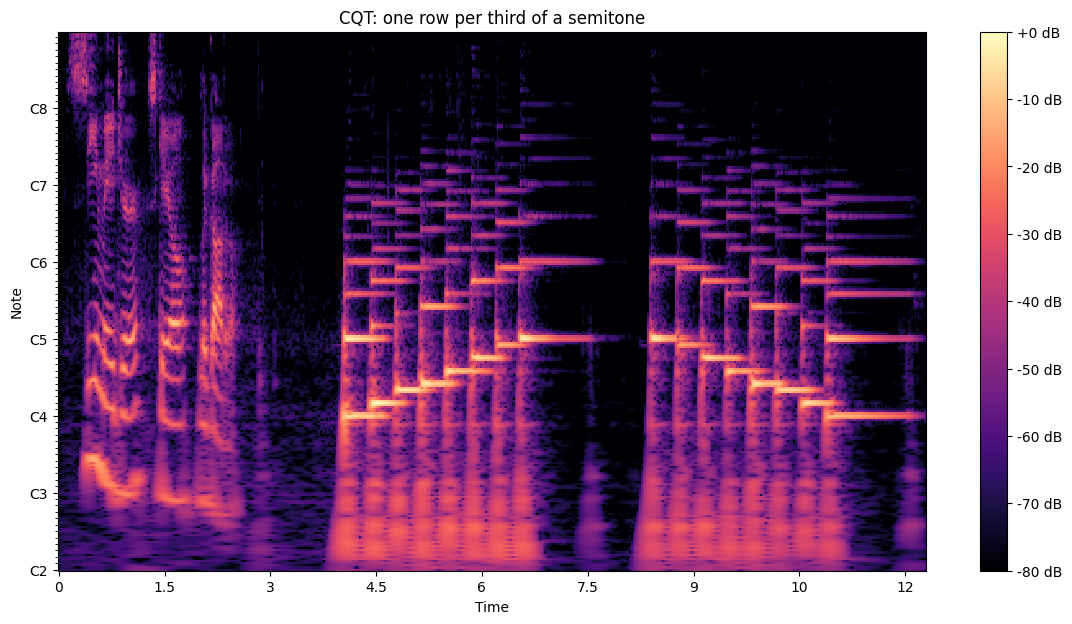

In [35]:
#Spectorgram with NOTES - CQT

FMIN = librosa.note_to_hz("C2")  # lowest bin, 65.4 Hz
BINS_PER_OCTAVE = 36             # 3 bins per semitone
N_OCTAVES = 7                    # C2 up to C9

cqt_magnitude = np.abs(librosa.cqt(
    y=trimmed, sr=sr, hop_length=HOP_LENGTH,
    fmin=FMIN, n_bins=BINS_PER_OCTAVE * N_OCTAVES, bins_per_octave=BINS_PER_OCTAVE,
))
cqt_db = librosa.amplitude_to_db(cqt_magnitude, ref=np.max, top_db=80)

print(f"CQT shape: {cqt_db.shape}  (frequency bins, frames)")

fig, ax = plt.subplots(figsize=(14, 7))
img = librosa.display.specshow(
    cqt_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="cqt_note",
    fmin=FMIN, bins_per_octave=BINS_PER_OCTAVE, ax=ax,
)
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set(title="CQT: one row per third of a semitone")
plt.show()

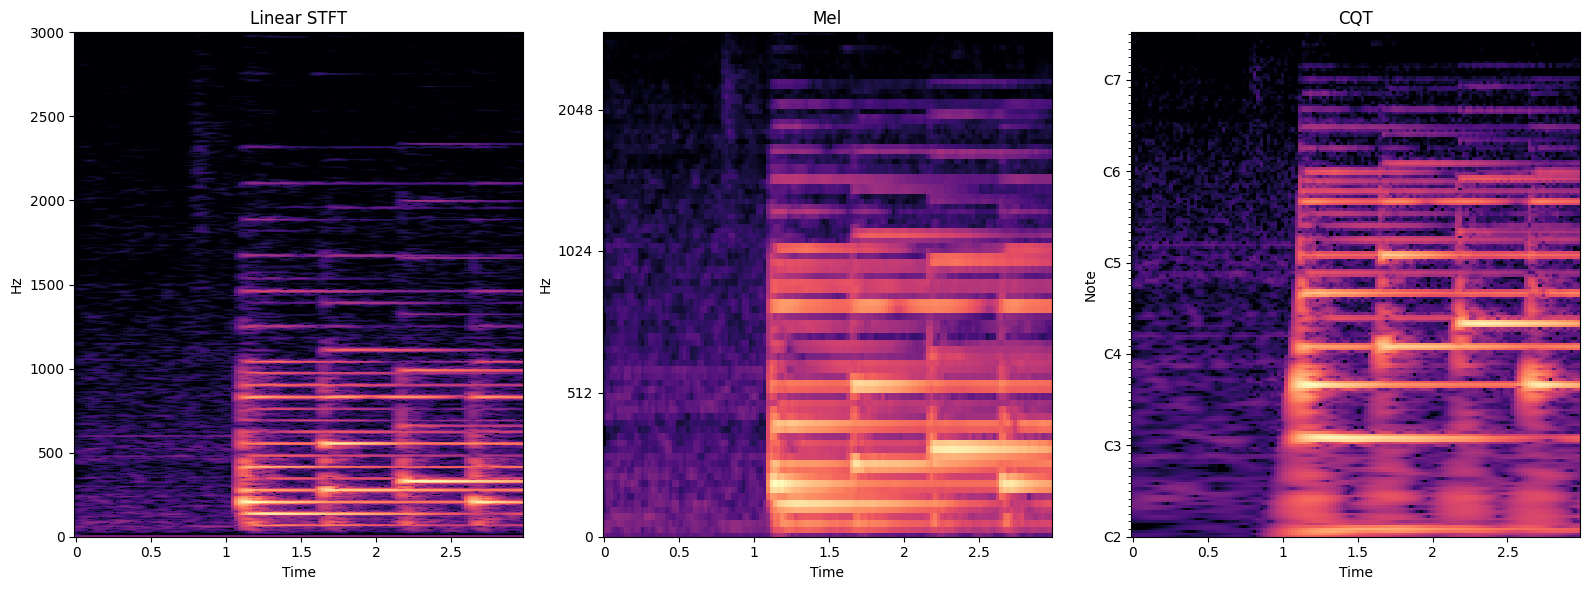

In [21]:
ZOOM_SECONDS = 3.0
zoom_frames = int(ZOOM_SECONDS * sr / HOP_LENGTH)

stft_db = librosa.amplitude_to_db(
    np.abs(librosa.stft(trimmed, n_fft=4096, hop_length=HOP_LENGTH)), ref=np.max,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
librosa.display.specshow(stft_db[:, :zoom_frames], sr=sr, hop_length=HOP_LENGTH,
                         x_axis="time", y_axis="linear", ax=axes[0])
axes[0].set(title="Linear STFT", ylim=(0, 3000))
librosa.display.specshow(mel_db[:, :zoom_frames], sr=sr, hop_length=HOP_LENGTH,
                         x_axis="time", y_axis="mel", fmax=8000, ax=axes[1])
axes[1].set(title="Mel", ylim=(0, 3000))
librosa.display.specshow(cqt_db[:, :zoom_frames], sr=sr, hop_length=HOP_LENGTH,
                         x_axis="time", y_axis="cqt_note", fmin=FMIN,
                         bins_per_octave=BINS_PER_OCTAVE, ax=axes[2])
axes[2].set(title="CQT", ylim=(FMIN, 3000))
plt.tight_layout()
plt.show()

In [24]:
### Looking at harmonics:

NOTE = "E4"
N_HARMONICS = 6

f0 = librosa.note_to_hz(NOTE)
harmonic_freqs = f0 * np.arange(1, N_HARMONICS + 1)

for k, freq in enumerate(harmonic_freqs, start=1):
    print(f"harmonic {k}: {freq:7.1f} Hz  ~ {librosa.hz_to_note(freq)}")

harmonic 1:   329.6 Hz  ~ E4
harmonic 2:   659.3 Hz  ~ E5
harmonic 3:   988.9 Hz  ~ B5
harmonic 4:  1318.5 Hz  ~ E6
harmonic 5:  1648.1 Hz  ~ G♯6
harmonic 6:  1977.8 Hz  ~ B6


E4 is loudest at frame 643 (14.93 s)


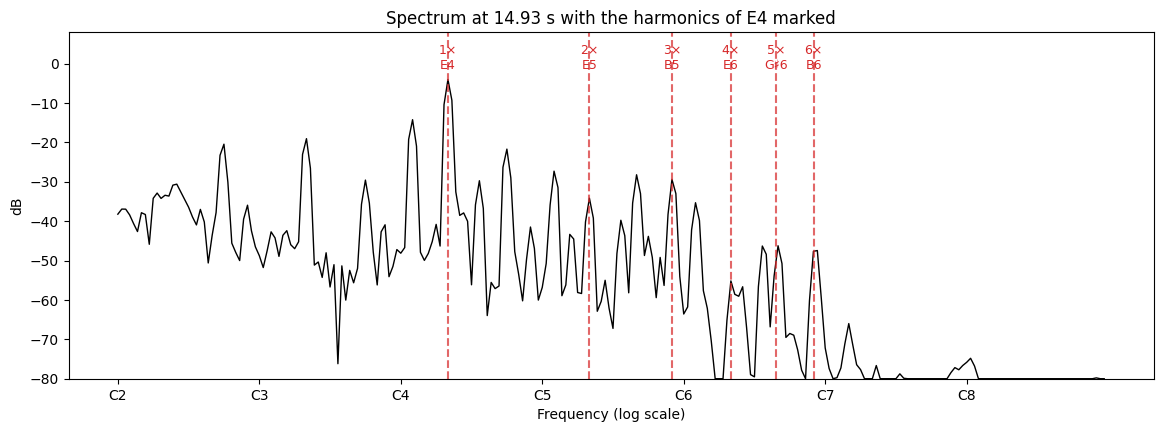

In [25]:
cqt_freqs = librosa.cqt_frequencies(BINS_PER_OCTAVE * N_OCTAVES, fmin=FMIN,
                                    bins_per_octave=BINS_PER_OCTAVE)
fundamental_bin = int(np.argmin(np.abs(cqt_freqs - f0)))
best_frame = int(np.argmax(cqt_db[fundamental_bin]))
best_time = librosa.frames_to_time(best_frame, sr=sr, hop_length=HOP_LENGTH)
print(f"{NOTE} is loudest at frame {best_frame} ({best_time:.2f} s)")

# One column of the CQT = the spectrum at that instant
spectrum = cqt_db[:, best_frame]

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(cqt_freqs, spectrum, color="black", lw=1)
for k, freq in enumerate(harmonic_freqs, start=1):
    ax.axvline(freq, color="tab:red", ls="--", alpha=0.7)
    ax.text(freq, spectrum.max() + 2, f"{k}×\n{librosa.hz_to_note(freq)}",
            ha="center", va="bottom", color="tab:red", fontsize=9)
ax.set_xscale("log", base=2)
ax.set_xticks(librosa.note_to_hz(["C2", "C3", "C4", "C5", "C6", "C7", "C8"]))
ax.set_xticklabels(["C2", "C3", "C4", "C5", "C6", "C7", "C8"])
ax.set(title=f"Spectrum at {best_time:.2f} s with the harmonics of {NOTE} marked",
       xlabel="Frequency (log scale)", ylabel="dB", ylim=(spectrum.min(), spectrum.max() + 12))
plt.show()

Detected 110 onsets. How many notes were actually played?


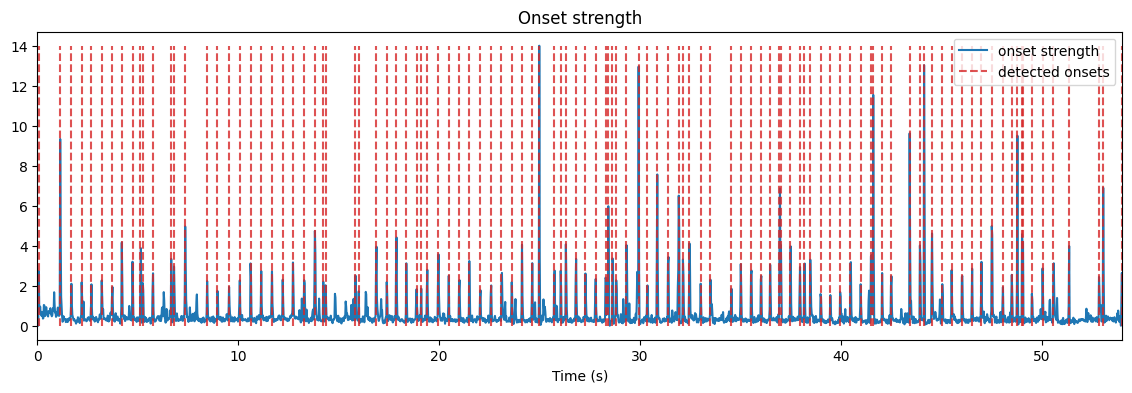

In [27]:
### ONSET DETECTION / STRENGTH

onset_env = librosa.onset.onset_strength(y=trimmed, sr=sr, hop_length=HOP_LENGTH)
onset_frames = librosa.onset.onset_detect(onset_envelope=onset_env, sr=sr,
                                          hop_length=HOP_LENGTH, units="frames")
onset_times = librosa.frames_to_time(onset_frames, sr=sr, hop_length=HOP_LENGTH)
frame_times = librosa.times_like(onset_env, sr=sr, hop_length=HOP_LENGTH)

print(f"Detected {len(onset_frames)} onsets. How many notes were actually played?")

fig, ax = plt.subplots()
ax.plot(frame_times, onset_env, label="onset strength")
ax.vlines(onset_times, 0, onset_env.max(), color="tab:red", ls="--", alpha=0.8, label="detected onsets")
ax.set(title="Onset strength", xlabel="Time (s)", xlim=(0, frame_times[-1]))
ax.legend(loc="upper right")
plt.show()

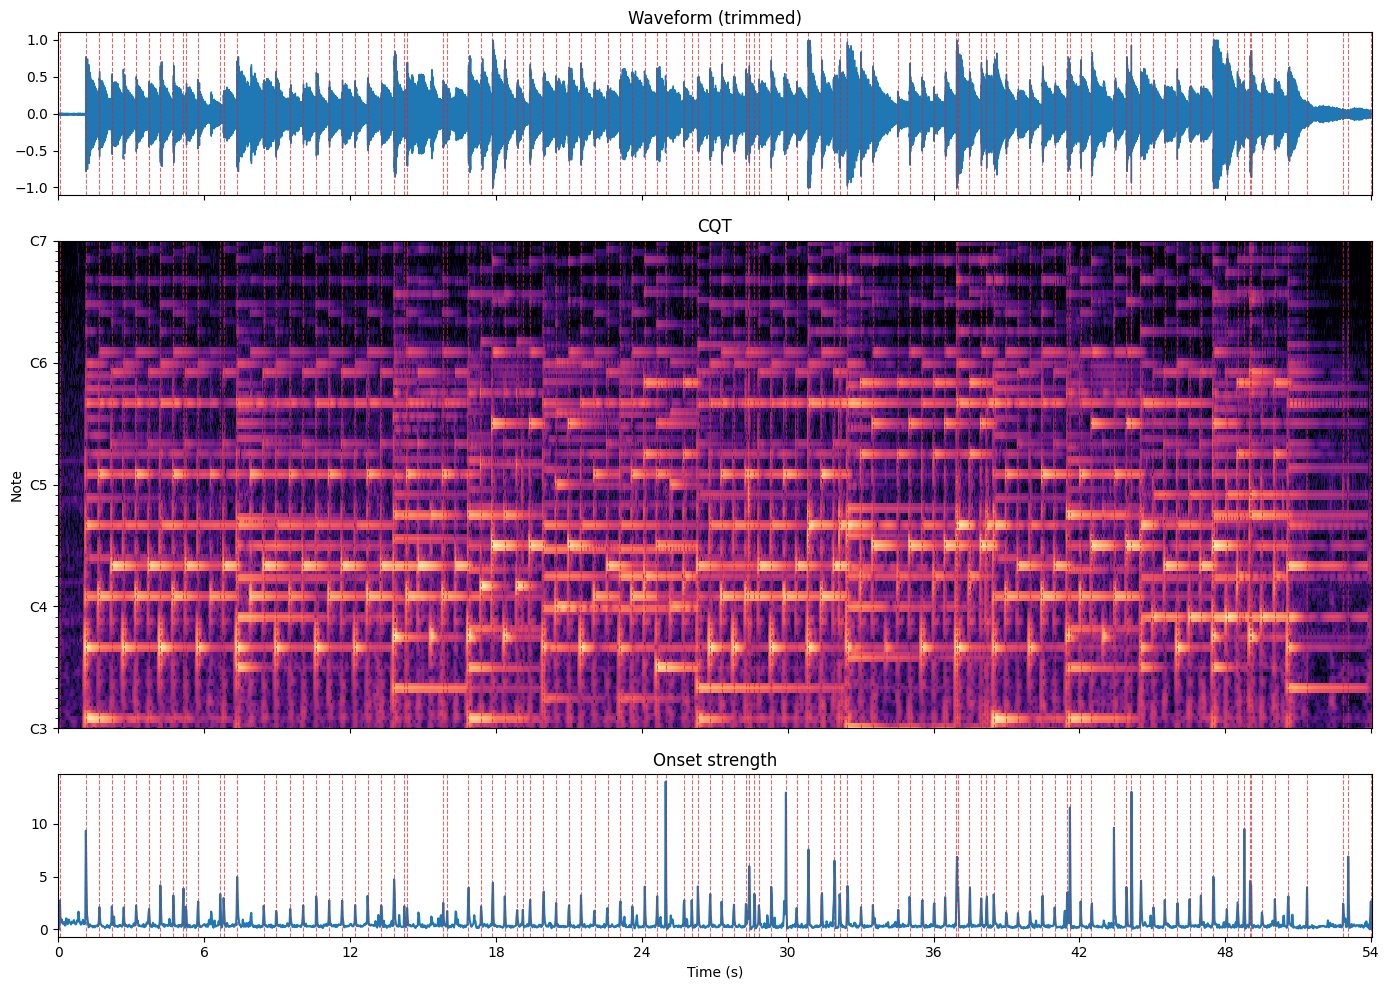

In [28]:
#All together:

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True,
                         gridspec_kw={"height_ratios": [1, 3, 1]})

librosa.display.waveshow(trimmed, sr=sr, ax=axes[0])
axes[0].set(title="Waveform (trimmed)", xlabel="")

librosa.display.specshow(cqt_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="cqt_note",
                         fmin=FMIN, bins_per_octave=BINS_PER_OCTAVE, ax=axes[1])
axes[1].set(title="CQT", ylim=(librosa.note_to_hz("C3"), librosa.note_to_hz("C7")), xlabel="")

axes[2].plot(frame_times, onset_env)
axes[2].set(title="Onset strength", xlabel="Time (s)")

for ax in axes:
    for t in onset_times:
        ax.axvline(t, color="tab:red", ls="--", lw=0.8, alpha=0.7)

plt.tight_layout()
plt.show()